# ✊✋✌️ Memprediksi Gestur Tangan: Gunting, Batu, Kertas

Notebook ini membangun model **Convolutional Neural Network (CNN)** untuk mengklasifikasikan gambar gestur tangan ke dalam 3 kelas: **paper (kertas)**, **rock (batu)**, dan **scissors (gunting)**.

**Alur kerja notebook:**
1. Memeriksa struktur folder dataset
2. Memuat data (train / validation / test)
3. Analisis dan visualisasi dataset
4. Membangun model CNN (dengan augmentasi data)
5. Melatih model
6. Memvisualisasikan grafik akurasi dan loss
7. Mengevaluasi model pada data test
8. Menyimpan model

**Dataset:** [Rock-Paper-Scissors Dataset (sanikamal)](https://www.kaggle.com/datasets/sanikamal/rock-paper-scissors-dataset) dari Kaggle.

## Langkah 1 — Cek Struktur Folder Dataset

Sel ini menelusuri seluruh isi folder `/kaggle/input` menggunakan `os.walk`, lalu mencetak folder mana saja yang berisi file beserta jumlah filenya.

**Tujuan:** memastikan dataset sudah tersedia dan mengetahui letak folder `train` dan `test` sebelum data dimuat.

In [1]:
# 1. cek struktur folder dataset
import os
for root, dirs, files in os.walk('/kaggle/input'):
    if files:
        print(root, '->', len(files), 'file')

### Mencari Folder Dasar (`BASE`) Secara Otomatis

Sel ini mencari folder yang di dalamnya terdapat sub-folder `train` **dan** `test`, lalu menyimpannya di variabel `BASE`.

> 💡 **Catatan:** pada output di sini hasilnya `BASE = None`, artinya dataset belum ditemukan di `/kaggle/input` pada saat sel ini dijalankan (dataset baru diunduh di langkah berikutnya lewat `kagglehub`). Sel ini bersifat opsional dan bisa dilewati.

In [2]:
import os
BASE = None
for root, dirs, files in os.walk('/kaggle/input'):
    if 'train' in dirs and 'test' in dirs:
        BASE = root
        break
print('BASE =', BASE)

BASE = None


## Langkah 2 — Memuat Data (Load Data)

Pada langkah ini dilakukan:
- **Import library:** NumPy, Matplotlib, TensorFlow/Keras, dan `kagglehub`.
- **Mengunduh dataset** dari Kaggle dengan `kagglehub.dataset_download(...)`.
- **Mencari folder `BASE`** yang memuat `train` dan `test`.
- **Menentukan parameter:** ukuran gambar `IMG = (150, 150)` piksel dan `BATCH = 32` gambar per batch.
- **Membuat tiga dataset** dengan `image_dataset_from_directory`:
  - `train_ds` → 80% dari folder `train` (**2016 gambar**) untuk melatih model
  - `val_ds` → 20% dari folder `train` (**504 gambar**) untuk validasi selama pelatihan
  - `test_ds` → folder `test` (**372 gambar**) untuk evaluasi akhir (`shuffle=False` agar urutan label tetap konsisten saat evaluasi)

Parameter `seed=42` memastikan pembagian train/validation selalu sama setiap kali dijalankan. Nama kelas diambil otomatis dari nama folder: `['paper', 'rock', 'scissors']`.

In [3]:
# 2. load data
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
import kagglehub

# unduh dataset dari Kaggle
path = kagglehub.dataset_download('sanikamal/rock-paper-scissors-dataset')
print('path =', path)

# cari folder yang berisi train dan test
BASE = None
for root, dirs, files in os.walk(path):
    if 'train' in dirs and 'test' in dirs:
        BASE = root
        break
print('BASE =', BASE)

IMG = (150, 150)
BATCH = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    BASE + '/train', validation_split=0.2, subset='training',
    seed=42, image_size=IMG, batch_size=BATCH)
val_ds = tf.keras.utils.image_dataset_from_directory(
    BASE + '/train', validation_split=0.2, subset='validation',
    seed=42, image_size=IMG, batch_size=BATCH)
test_ds = tf.keras.utils.image_dataset_from_directory(
    BASE + '/test', image_size=IMG, batch_size=BATCH, shuffle=False)

class_names = train_ds.class_names
print(class_names)

Using Colab cache for faster access to the 'rock-paper-scissors-dataset' dataset.
path = /kaggle/input/rock-paper-scissors-dataset
BASE = /kaggle/input/rock-paper-scissors-dataset/Rock-Paper-Scissors
Found 2520 files belonging to 3 classes.
Using 2016 files for training.
Found 2520 files belonging to 3 classes.
Using 504 files for validation.
Found 372 files belonging to 3 classes.
['paper', 'rock', 'scissors']


## Langkah 3 — Analisis dan Visualisasi Dataset

Sebelum membuat model, kita perlu memahami datanya terlebih dahulu:

1. **Distribusi kelas** — diagram batang yang menampilkan jumlah gambar per kelas pada data train. Hasilnya **seimbang** (masing-masing 840 gambar), sehingga model tidak cenderung condong ke satu kelas dan akurasi menjadi metrik yang layak digunakan.
2. **Contoh gambar** — menampilkan 8 gambar acak dari satu batch beserta labelnya, untuk memastikan gambar terbaca dengan benar dan label sesuai.

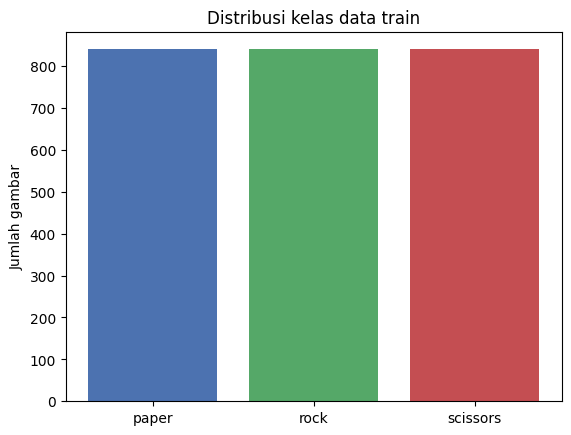

{'paper': 840, 'rock': 840, 'scissors': 840}


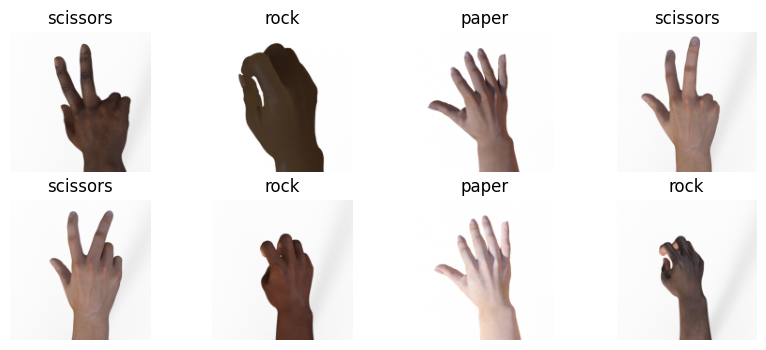

In [4]:
# 3: analisis dan visualisasi dataset
# Distribusi kelas (train)
counts = {c: len(os.listdir(f'{BASE}/train/{c}')) for c in class_names}
plt.bar(counts.keys(), counts.values(), color=['#4c72b0', '#55a868', '#c44e52'])
plt.title('Distribusi kelas data train')
plt.ylabel('Jumlah gambar')
plt.show()
print(counts)

# Contoh gambar
plt.figure(figsize=(10, 4))
for images, labels in train_ds.take(1):
    for i in range(8):
        plt.subplot(2, 4, i + 1)
        plt.imshow(images[i].numpy().astype('uint8'))
        plt.title(class_names[labels[i]])
        plt.axis('off')
plt.show()

### Memuat Ulang Dataset

Sel ini mengulang proses pembuatan `train_ds`, `val_ds`, dan `test_ds` seperti pada Langkah 2, namun mencari `BASE` langsung dari `/kaggle/input`. Hasilnya sama persis (2016 train, 504 validation, 372 test) dan nama kelas tetap `['paper', 'rock', 'scissors']`.

> 💡 Sel ini bersifat redundan jika Langkah 2 sudah dijalankan, tetapi berguna bila notebook dijalankan ulang dari sini (misalnya setelah runtime di-restart di Kaggle).

In [5]:
import os
import tensorflow as tf

# cari folder dataset otomatis
BASE = None
for root, dirs, files in os.walk('/kaggle/input'):
    if 'train' in dirs and 'test' in dirs:
        BASE = root
        break
print('BASE =', BASE)

IMG = (150, 150)
BATCH = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    BASE + '/train', validation_split=0.2, subset='training',
    seed=42, image_size=IMG, batch_size=BATCH)
val_ds = tf.keras.utils.image_dataset_from_directory(
    BASE + '/train', validation_split=0.2, subset='validation',
    seed=42, image_size=IMG, batch_size=BATCH)
test_ds = tf.keras.utils.image_dataset_from_directory(
    BASE + '/test', image_size=IMG, batch_size=BATCH, shuffle=False)

class_names = train_ds.class_names
print(class_names)

BASE = /kaggle/input/rock-paper-scissors-dataset/Rock-Paper-Scissors
Found 2520 files belonging to 3 classes.
Using 2016 files for training.
Found 2520 files belonging to 3 classes.
Using 504 files for validation.
Found 372 files belonging to 3 classes.
['paper', 'rock', 'scissors']


## Langkah 4 — Membangun Model CNN Custom

Model dibuat dengan `Sequential` dan terdiri dari beberapa bagian:

**① Augmentasi data** (hanya aktif saat training) — membuat variasi gambar agar model lebih general dan tidak *overfitting*:
- `RandomFlip('horizontal')` → membalik gambar secara horizontal
- `RandomRotation(0.1)` → memutar gambar secara acak
- `RandomZoom(0.1)` → memperbesar/memperkecil gambar secara acak

**② Normalisasi** — `Rescaling(1./255)` mengubah nilai piksel dari rentang 0–255 menjadi 0–1 agar pelatihan lebih stabil.

**③ Ekstraksi fitur** — 4 blok `Conv2D` + `MaxPooling2D` dengan jumlah filter 32 → 64 → 128 → 128. Lapisan awal menangkap pola sederhana (tepi, garis), lapisan yang lebih dalam menangkap bentuk yang lebih kompleks (jari, kontur tangan). `MaxPooling` memperkecil ukuran peta fitur.

**④ Klasifikasi:**
- `Flatten` → meratakan peta fitur menjadi vektor
- `Dropout(0.3)` → mematikan 30% neuron secara acak untuk mengurangi overfitting
- `Dense(128, relu)` → lapisan tersembunyi
- `Dense(3, softmax)` → output berupa probabilitas untuk 3 kelas

**⑤ Compile:**
- *Optimizer:* Adam dengan learning rate `1e-3`
- *Loss:* `sparse_categorical_crossentropy` (cocok karena label berupa bilangan bulat, bukan one-hot)
- *Metrik:* akurasi

In [6]:

#4: model custom CNN (sudah termasuk augmentasi)
augment = tf.keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

model = models.Sequential([
    layers.Input(shape=IMG + (3,)),
    augment,
    layers.Rescaling(1./255),

    layers.Conv2D(32, 3, activation='relu', padding='same'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation='relu', padding='same'),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation='relu', padding='same'),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation='relu', padding='same'),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dropout(0.3),
    layers.Dense(128, activation='relu'),
    layers.Dense(3, activation='softmax'),
])

model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

## Langkah 5 — Training Model

Model dilatih dengan `model.fit` maksimal **30 epoch** menggunakan `train_ds`, dan dipantau lewat `val_ds`. Dua *callback* digunakan:

- **`EarlyStopping(patience=6, restore_best_weights=True)`** — menghentikan pelatihan jika performa validasi tidak membaik selama 6 epoch, lalu mengembalikan bobot terbaik.
- **`ReduceLROnPlateau(factor=0.5, patience=3)`** — memperkecil learning rate hingga setengahnya jika tidak ada perbaikan selama 3 epoch, supaya model bisa menyempurnakan bobotnya dengan langkah yang lebih halus.

Hasil pelatihan disimpan di variabel `history` untuk divisualisasikan pada langkah berikutnya. Terlihat akurasi train dan validasi mencapai sekitar **100%** di epoch-epoch akhir, dengan learning rate yang turun bertahap.

In [7]:
#5: training
callbacks = [
    tf.keras.callbacks.EarlyStopping(patience=6, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=3),
]
history = model.fit(train_ds, validation_data=val_ds, epochs=30, callbacks=callbacks)

Epoch 1/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 18s 173ms/step - accuracy: 0.5238 - loss: 0.9183 - val_accuracy: 0.8651 - val_loss: 0.3598 - learning_rate: 0.0010
Epoch 2/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 12s 107ms/step - accuracy: 0.8894 - loss: 0.2987 - val_accuracy: 0.9802 - val_loss: 0.0930 - learning_rate: 0.0010
Epoch 3/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 11s 124ms/step - accuracy: 0.9618 - loss: 0.1234 - val_accuracy: 0.9960 - val_loss: 0.0379 - learning_rate: 0.0010
Epoch 4/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 5s 85ms/step - accuracy: 0.9826 - loss: 0.0526 - val_accuracy: 1.0000 - val_loss: 0.0046 - learning_rate: 0.0010
Epoch 5/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 7s 112ms/step - accuracy: 0.9891 - loss: 0.0325 - val_accuracy: 1.0000 - val_loss: 0.0020 - learning_rate: 0.0010
Epoch 6/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 9s 86ms/step - accuracy: 0.9717 - loss: 0.0784 - val_accuracy: 0.9960 - val_loss: 0.0231 - learning_rate: 0.0010
Epoch 7/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 7s 106ms/step - accuracy: 0.9876 - loss: 0.0387 -

## Langkah 6 — Grafik Akurasi dan Loss

Dua grafik dibuat dari `history`:
- **Akurasi** (kiri) — perbandingan akurasi *train* vs *validation* tiap epoch
- **Loss** (kanan) — perbandingan loss *train* vs *validation* tiap epoch

**Cara membaca:** akurasi yang naik dan loss yang turun menandakan model belajar dengan baik. Jika kurva train dan validation berjalan berdekatan, berarti model tidak mengalami overfitting yang parah.

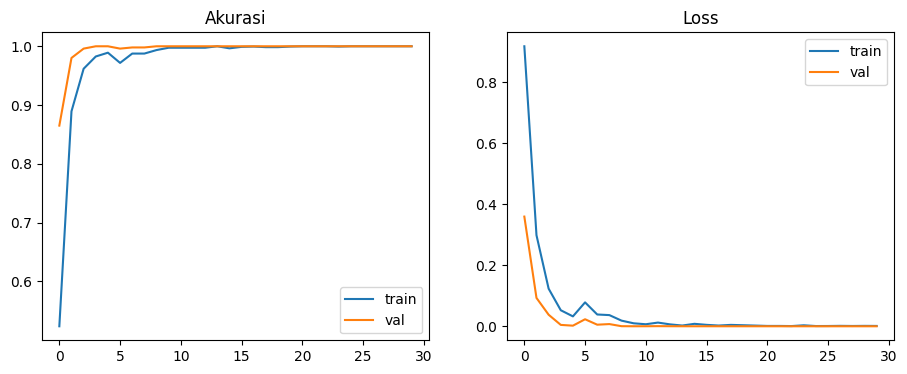

In [8]:
# 6: grafik akurasi dan loss
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(history.history['accuracy'], label='train')
ax[0].plot(history.history['val_accuracy'], label='val')
ax[0].set_title('Akurasi'); ax[0].legend()
ax[1].plot(history.history['loss'], label='train')
ax[1].plot(history.history['val_loss'], label='val')
ax[1].set_title('Loss'); ax[1].legend()
plt.show()

## Langkah 7 — Evaluasi pada Data Test

Model diuji pada `test_ds`, yaitu data yang **belum pernah dilihat** selama pelatihan, sehingga hasilnya mencerminkan performa nyata. Langkah-langkahnya:

1. `model.evaluate` menghitung loss dan akurasi test → **akurasi test ≈ 98,66%**.
2. Mengumpulkan label asli (`y_true`) dan prediksi model (`y_pred`, diambil dengan `argmax` dari probabilitas softmax).
3. **Classification report** — menampilkan *precision*, *recall*, dan *f1-score* per kelas.
4. **Confusion matrix** (heatmap) — menunjukkan jumlah prediksi benar (diagonal) dan salah (di luar diagonal) untuk tiap kelas.

**Interpretasi singkat:** kelas `scissors` diprediksi sempurna, sedangkan sedikit kesalahan terjadi antara `rock` dan `paper` (recall `rock` 0,96 dan precision `paper` 0,96), artinya sebagian kecil gambar batu terprediksi sebagai kertas.

12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 131ms/step - accuracy: 0.9866 - loss: 0.0650
Test accuracy: 0.9866
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 97ms/step
              precision    recall  f1-score   support

       paper       0.96      1.00      0.98       124
        rock       1.00      0.96      0.98       124
    scissors       1.00      1.00      1.00       124

    accuracy                           0.99       372
   macro avg       0.99      0.99      0.99       372
weighted avg       0.99      0.99      0.99       372



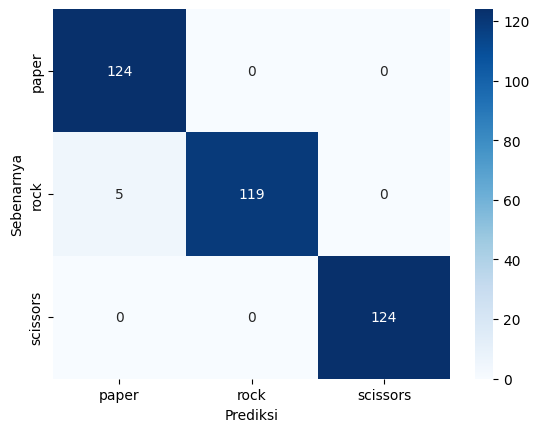

In [9]:
#7: evaluasi di data test
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

test_loss, test_acc = model.evaluate(test_ds)
print(f'Test accuracy: {test_acc:.4f}')

y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_pred = np.argmax(model.predict(test_ds), axis=1)

print(classification_report(y_true, y_pred, target_names=class_names))
sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt='d',
            xticklabels=class_names, yticklabels=class_names, cmap='Blues')
plt.xlabel('Prediksi'); plt.ylabel('Sebenarnya'); plt.show()

## Langkah 8 — Menyimpan Model

Model yang sudah dilatih disimpan ke file `rps_cnn.keras` (arsitektur + bobot). File ini bisa dimuat kembali dengan `tf.keras.models.load_model('rps_cnn.keras')` untuk melakukan prediksi tanpa training ulang, misalnya saat **deployment** ke aplikasi web atau mobile.

In [10]:
# 8: simpan model (untuk deployment nanti)
model.save('rps_cnn.keras')

## 📌 Kesimpulan

- Dataset **seimbang** (840 gambar per kelas) sehingga akurasi adalah metrik yang tepat.
- Model CNN custom dengan augmentasi mencapai **akurasi test ≈ 98,66%**.
- Akurasi validasi mencapai 100%, sedikit lebih tinggi dari akurasi test. Ini wajar karena dataset ini relatif sederhana (latar belakang seragam), namun bisa jadi tanda bahwa performa pada foto dengan latar atau pencahayaan berbeda akan lebih rendah.
- **Ide pengembangan:** uji dengan foto asli dari kamera, tambah variasi latar dan pencahayaan, coba *transfer learning* (misalnya MobileNetV2), atau buat aplikasi prediksi real-time.